In [10]:
import sys
!{sys.executable} -m pip install category_encoders
!{sys.executable} -m pip install xgboost

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import category_encoders as ce
from category_encoders import HashingEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,precision_recall_curve
from xgboost import XGBClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans,AgglomerativeClustering,SpectralClustering,DBSCAN,MiniBatchKMeans
from collections import Counter
from scipy.stats import mode

In [12]:
data=pd.read_csv(r"C:\Users\tambe\Downloads\Data Mining Project\dataset\SAML-D.csv")

In [13]:
data.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [14]:
data.shape

(9504852, 12)

In [15]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    str    
 1   Date                    str    
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        str    
 6   Received_currency       str    
 7   Sender_bank_location    str    
 8   Receiver_bank_location  str    
 9   Payment_type            str    
 10  Is_laundering           int64  
 11  Laundering_type         str    
dtypes: float64(1), int64(3), str(8)
memory usage: 870.2 MB


In [16]:
#Preprocessing

In [17]:
#finding missing val
data.isnull().sum()

Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

In [18]:
#finding duplicate
data.duplicated().sum()

np.int64(0)

In [19]:
#finding garbage val
for i in data.select_dtypes(include="object").columns:
    print(data[i].value_counts())
    print("---"*10)

C:\Users\tambe\AppData\Local\Temp\ipykernel_15080\1035293368.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for i in data.select_dtypes(include="object").columns:


Time
15:22:42    201
11:35:00    199
14:09:05    199
14:49:56    198
14:01:16    196
           ... 
04:04:46     14
03:38:32     14
03:03:05     13
02:29:43     13
03:39:29     12
Name: count, Length: 86400, dtype: int64
------------------------------
Date
2023-02-09    36645
2023-02-01    35910
2023-02-06    35038
2023-02-22    34566
2022-12-23    34156
              ...  
2022-12-31    25808
2022-10-30    25298
2022-10-23    23719
2022-10-07    20892
2023-08-23     8400
Name: count, Length: 321, dtype: int64
------------------------------
Payment_currency
UK pounds          9099293
Euro                117164
Turkish lira         27996
Swiss franc          27492
Dirham               27263
Pakistani rupee      27196
Naira                27143
US dollar            26061
Yen                  25562
Moroccan dirham      25395
Mexican Peso         24852
Albanian lek         24778
Indian rupee         24657
Name: count, dtype: int64
------------------------------
Received_currency
UK pounds

In [20]:
data.describe(include="object")


C:\Users\tambe\AppData\Local\Temp\ipykernel_15080\127476290.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.describe(include="object")


,Time,Date,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Laundering_type
count,9504852,9504852,9504852,9504852,9504852,9504852,9504852,9504852
unique,86400,321,13,13,18,18,7,28
top,15:22:42,2023-02-09,UK pounds,UK pounds,UK,UK,Credit card,Normal_Small_Fan_Out
freq,201,36645,9099293,8783655,9183088,8864634,2012909,3477717


In [21]:
data.describe()

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9.504852e+06,9.504852e+06
mean,5.006619e+09,5.006006e+09,8.762968e+03,1.038733e-03
std,2.885814e+09,2.884763e+09,2.561495e+04,3.221263e-02
min,9.018000e+03,9.018000e+03,3.730000e+00,0.000000e+00
25%,2.513133e+09,2.513219e+09,2.143688e+03,0.000000e+00
50%,5.001017e+09,5.002572e+09,6.113720e+03,0.000000e+00
75%,7.505051e+09,7.502397e+09,1.045846e+04,0.000000e+00
max,9.999987e+09,9.999971e+09,1.261850e+07,1.000000e+00


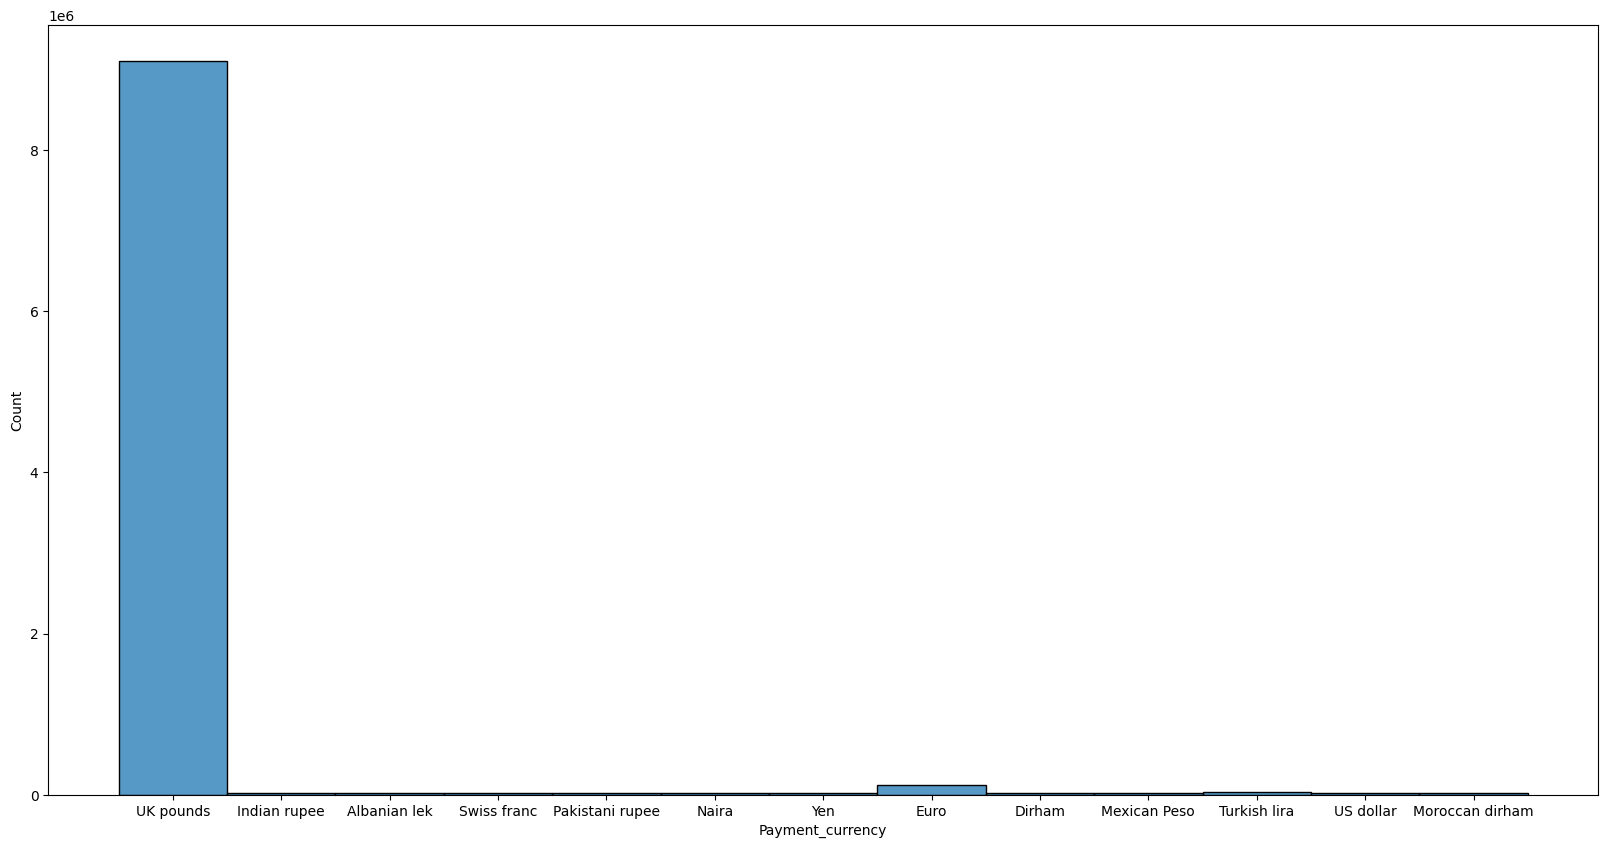

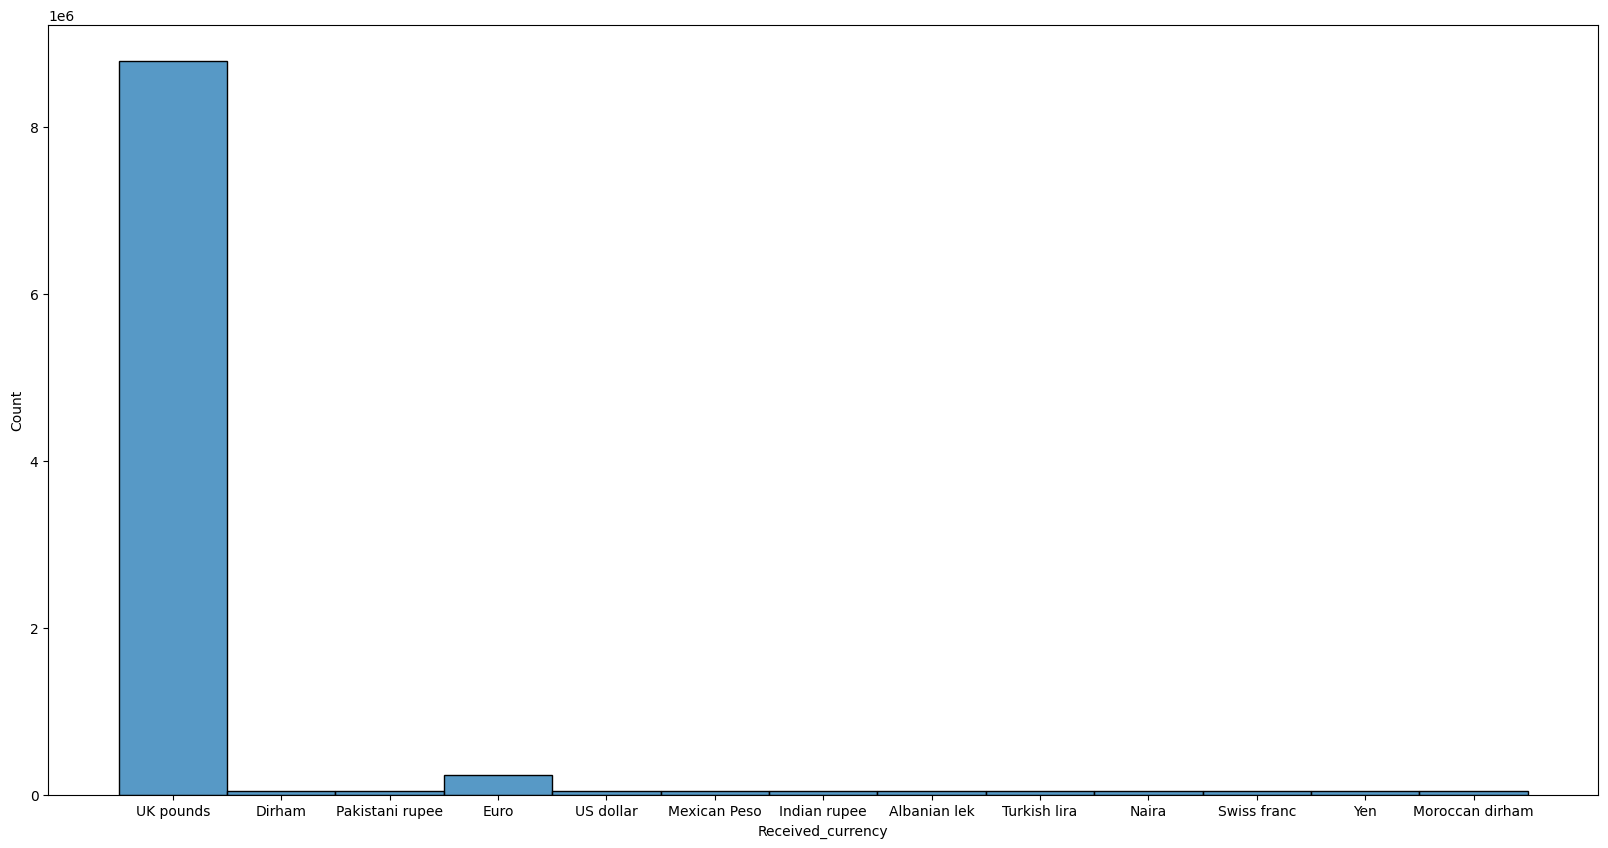

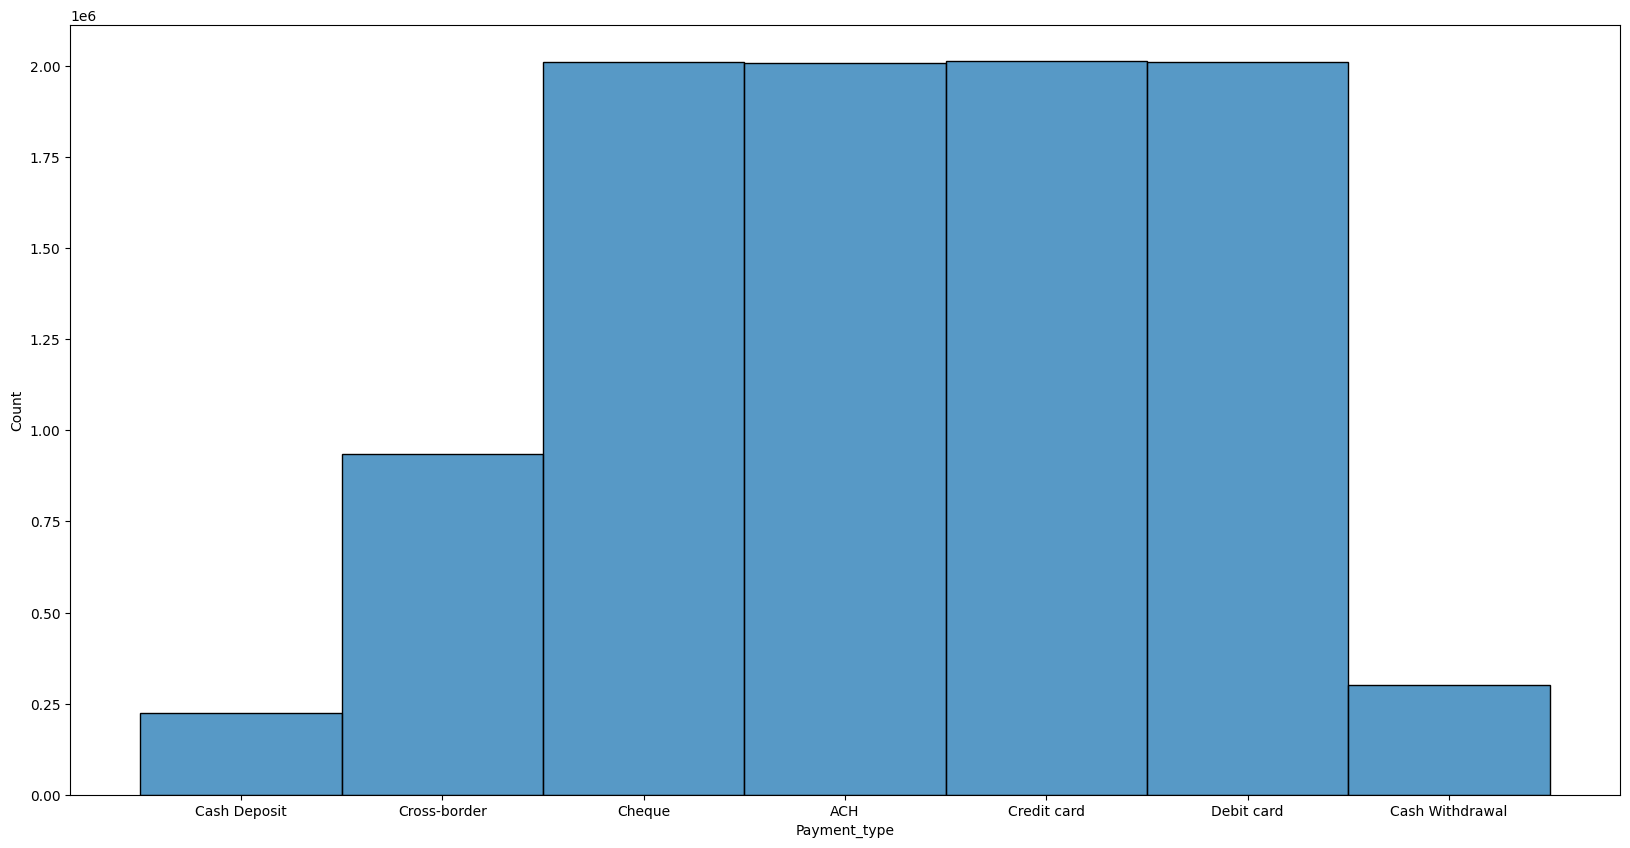

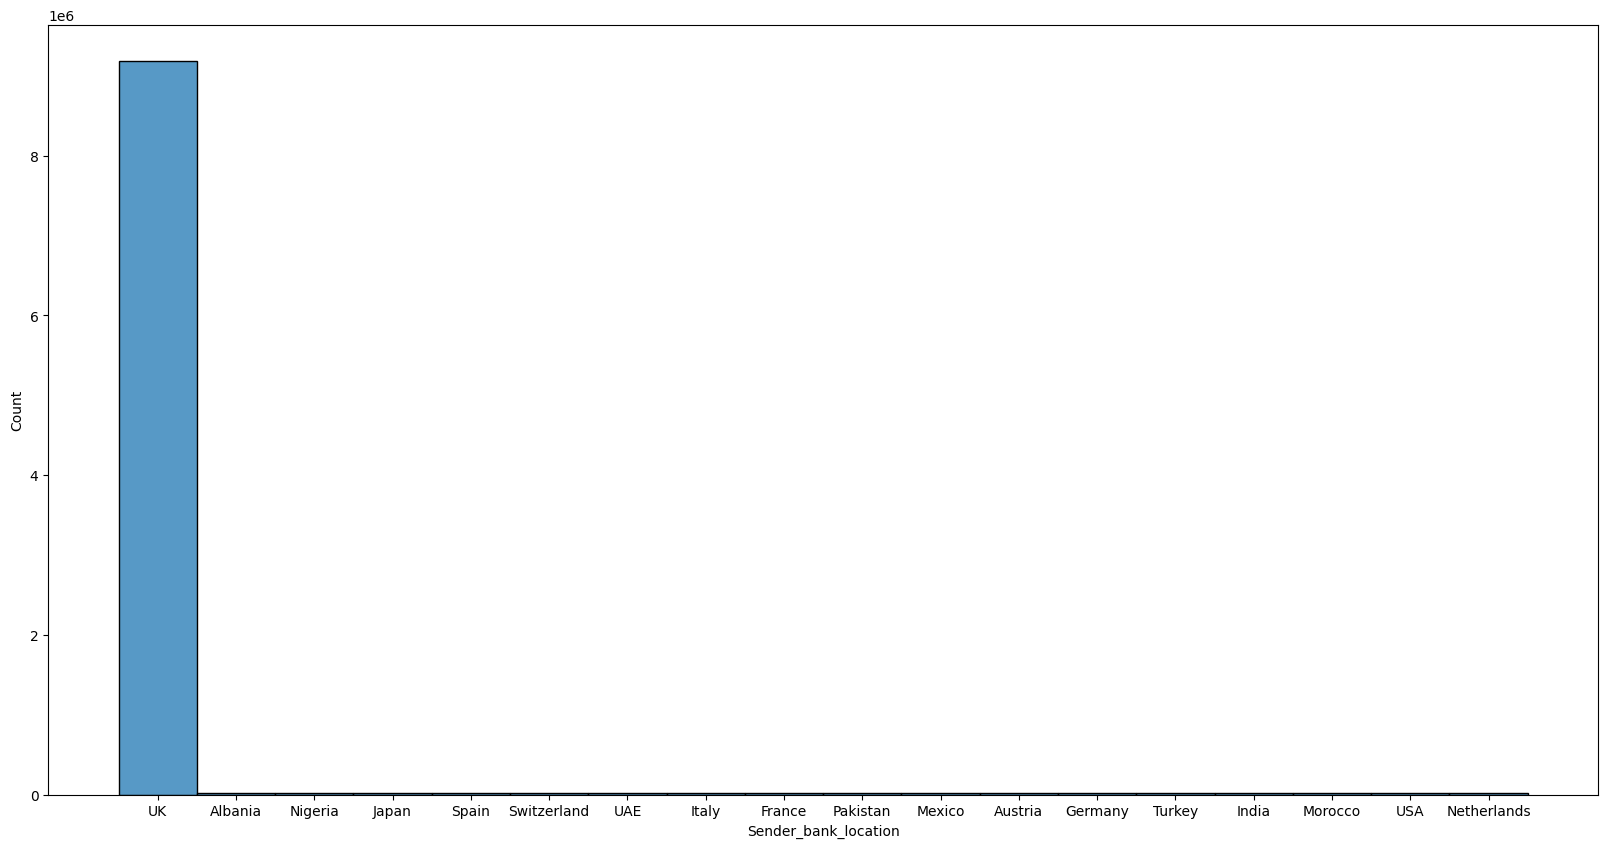

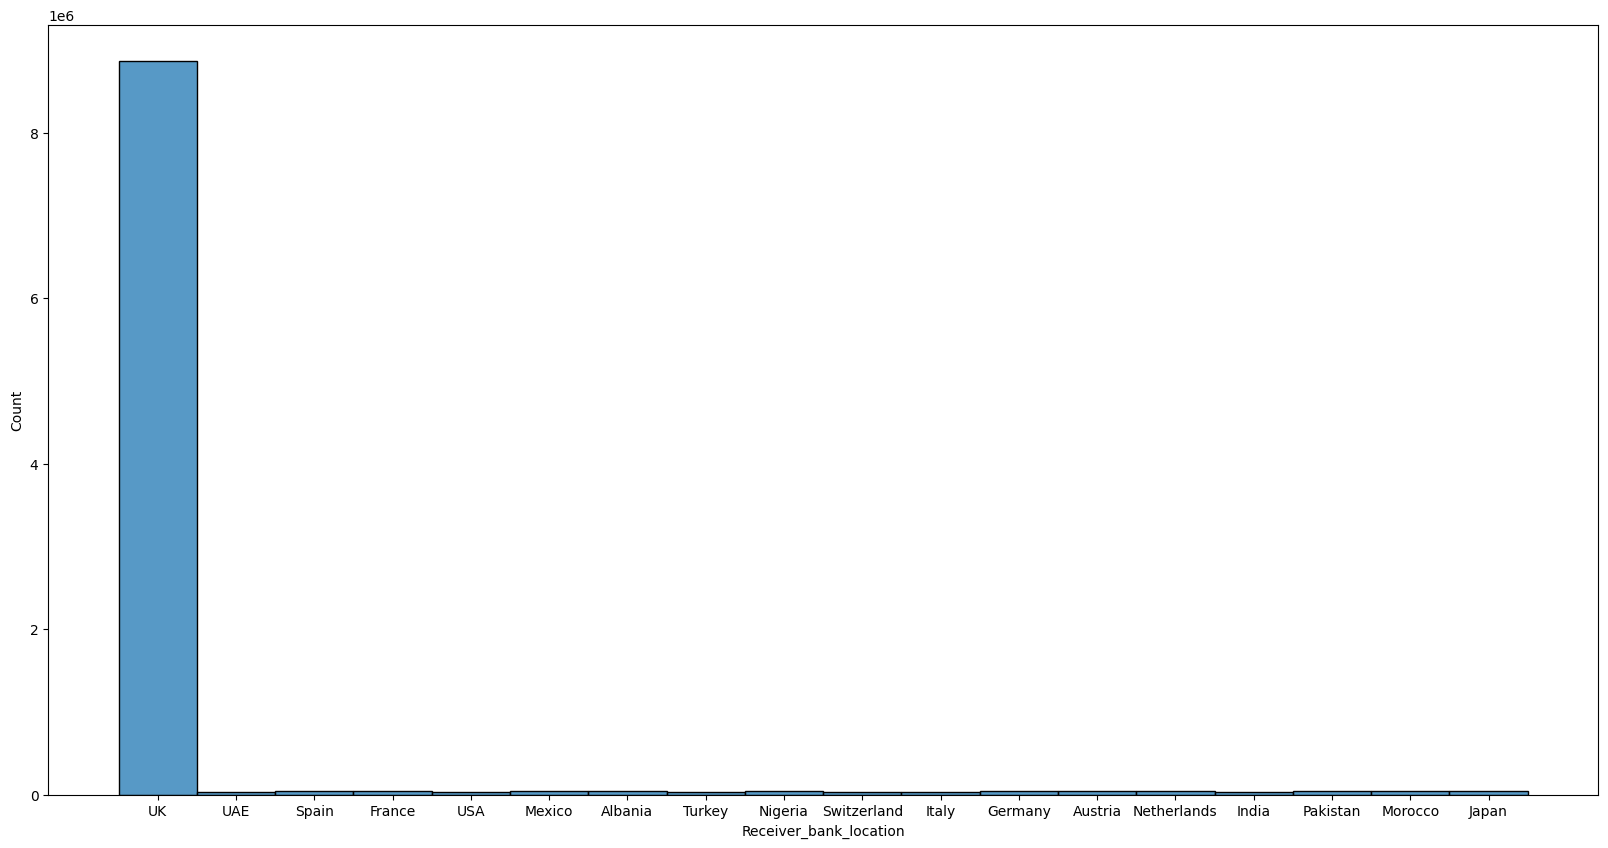

In [22]:
plot_columns=["Payment_currency","Received_currency","Payment_type","Sender_bank_location","Receiver_bank_location"]
for i in plot_columns:
    plt.figure(figsize=(20,10))
    sns.histplot(data=data,x=i)
    plt.show()

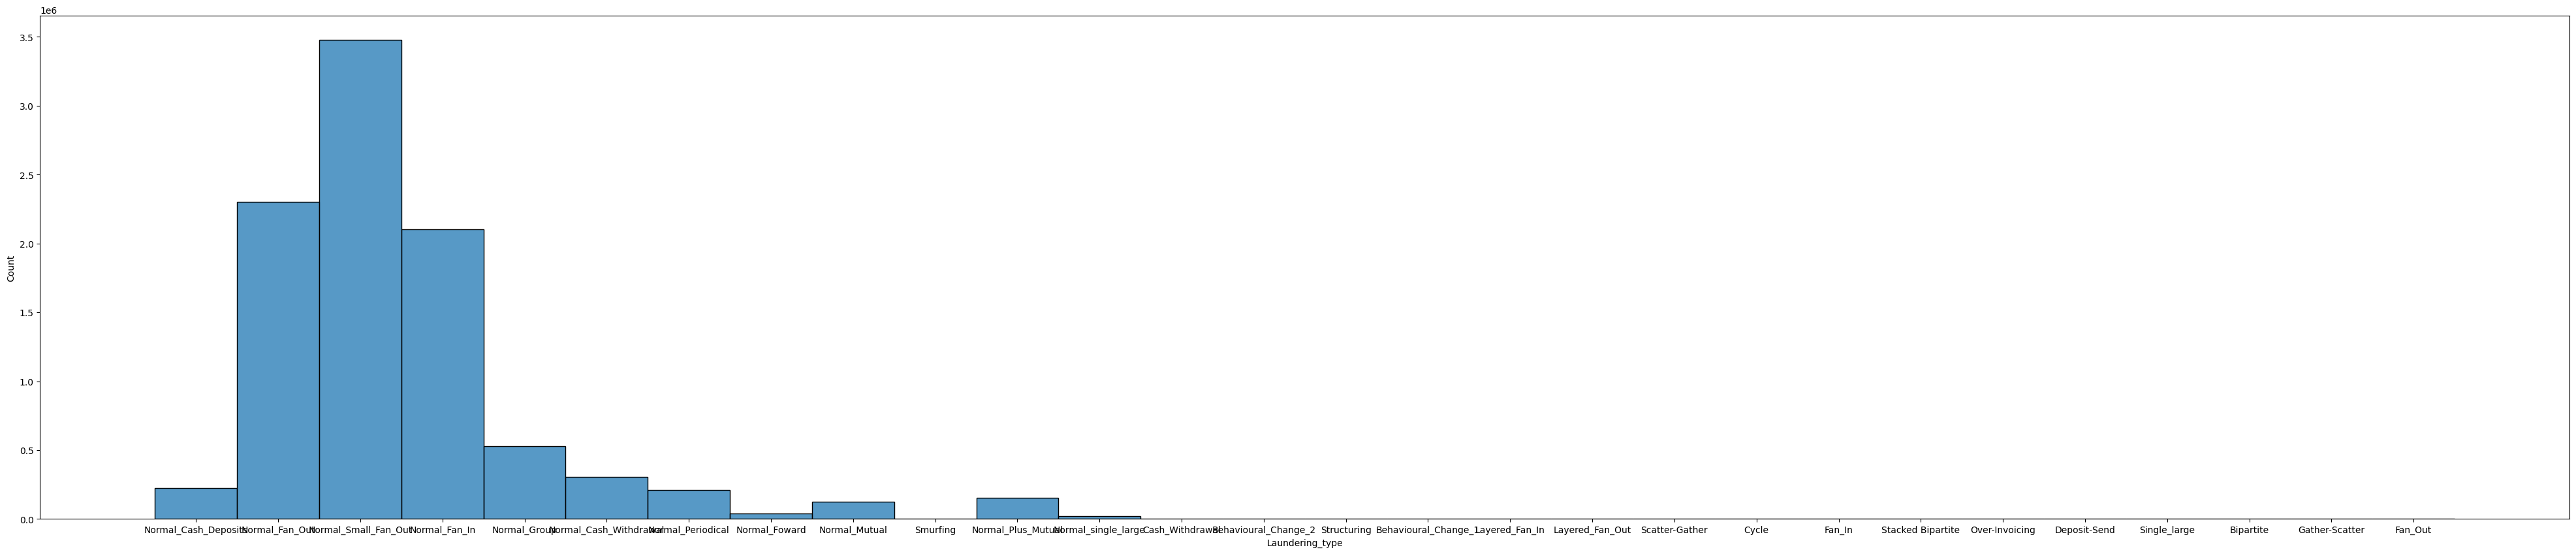

In [23]:
#plotting this seperately because the laundering types overlap 
plot_col=["Laundering_type"]
for i in plot_col:
    plt.figure(figsize=(50,10))
    sns.histplot(data=data,x=i)
    plt.show()

In [24]:
#seperating target attribute
x=data.drop(columns=["Is_laundering","Sender_account","Receiver_account"])
y=data["Is_laundering"]

In [25]:
#seperating categorical and numerical attributes
cat_cols = x.select_dtypes(include="object").columns.tolist()
num_cols = x.select_dtypes(exclude="object").columns.tolist()



C:\Users\tambe\AppData\Local\Temp\ipykernel_15080\726605963.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = x.select_dtypes(include="object").columns.tolist()


In [26]:
#encoding to convert categorical values to numerical values in order to train the model
#tried OneHotEncoder... didn't work. Ran into MemoryError. Got 86,819 features ~6tb after encoding
#tried binary encoder. again ran tinto MemeoryError (Unable to allocate 2.97 GiB for an array with shape (42, 9504852) and data type int64)
#Using Hashing Enocder. Good for High Cardinality Data set and doesn't give MemoryError 
hash_enc = HashingEncoder(
    cols=cat_cols,
    n_components = 32,
    drop_invariant=True
)

x_encoded= hash_enc.fit_transform(x)

In [27]:
#converted Categorical data to numeric (Amount is already NUmeric)
x_encoded

,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,...,col_23,col_24,col_25,col_26,col_27,col_28,col_29,col_30,col_31,Amount
0,1,0,0,0,0,1,0,0,0,2,...,0,0,0,1,0,0,0,0,0,1459.15
1,1,0,0,0,0,1,0,0,0,1,...,0,0,0,0,0,1,1,0,0,6019.64
2,1,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,14328.44
3,1,0,0,0,0,0,0,0,0,2,...,0,0,0,1,0,0,0,0,0,11895.00
4,1,0,0,0,0,1,0,0,0,2,...,0,0,0,2,0,0,0,0,0,115.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9504847,0,1,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,2247.25
9504848,0,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,1,0,0,927.18
9504849,0,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,1,0,0,1455.14
9504850,0,0,0,0,0,0,0,0,1,2,...,0,0,0,0,0,0,0,0,0,25995.70


In [28]:
#Scaling the encoded data(All features made equally important. Also Logistic Regression requires Scaled Data)
scaler = StandardScaler()
x_scaled=scaler.fit_transform(x_encoded)

In [29]:
x_scaled

array([[ 3.84096824, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712, -0.28513884],
       [ 3.84096824, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712, -0.10709868],
       [ 3.84096824, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712,  0.21727437],
       ...,
       [-0.25204253, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712, -0.28529539],
       [-0.25204253, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712,  0.67276068],
       [-0.25204253, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712,  0.03213406]], shape=(9504852, 33))

In [30]:
#Classification

In [31]:
#Splitting Train Test 
X_Train,X_Test,Y_Train,Y_Test = train_test_split(
    x_scaled,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [32]:
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal (Pred)', 'Fraud (Pred)'],
                yticklabels=['Normal (Actual)', 'Fraud (Actual)'])
    
    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

In [33]:
#Trying Logistic Regression
model = LogisticRegression(max_iter=500,class_weight="balanced")

model.fit(X_Train,Y_Train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [34]:
logreg_predict=model.predict(X_Test)

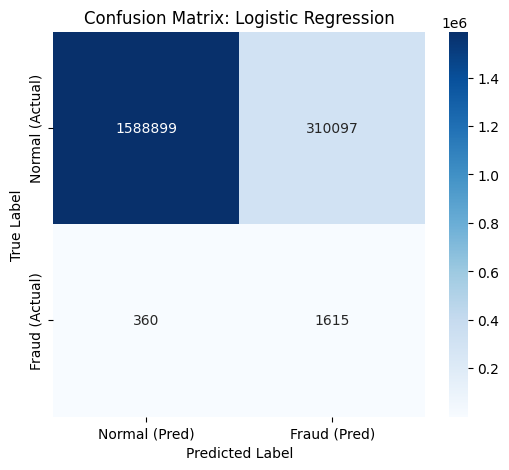

In [35]:
plot_confusion_matrix(Y_Test, logreg_predict, "Logistic Regression")


In [36]:
print(classification_report(Y_Test,logreg_predict))

              precision    recall  f1-score   support

           0       1.00      0.84      0.91   1898996
           1       0.01      0.82      0.01      1975

    accuracy                           0.84   1900971
   macro avg       0.50      0.83      0.46   1900971
weighted avg       1.00      0.84      0.91   1900971



In [37]:
#Terrible result as the data set is very very unbalanced (0.01% of ouput of Is_Laundering = 1)
#Logsistic regression for this type of data set is not good (it assumes linear relationships not good for complex relationships)
#KNN is also not good for these kinds of data set 
#Trying a model which handles imbalance of data set(XGBoost or LightGBM)


In [38]:
#XGBoost Model(takes care of imbalance in data and also assumes non-linear raeltionship)
#We already have the train-test split

#Computing the imbalance ratio
neg = (Y_Train==0).sum()
pos = (Y_Train==1).sum()

scale_pos_weight = neg/pos

print("Scaled Positive Weight : ", scale_pos_weight)

Scaled Positive Weight :  961.7603190681185


In [39]:
#Training the model
model = XGBClassifier(
    #Hyperparameter Tuning
    n_estimators=500,          
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,

    # performance tuning
    tree_method='hist',
    eval_metric='aucpr', #changed from logloss
    n_jobs=-1
)

model.fit(X_Train, Y_Train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [40]:
xgb_pred= model.predict(X_Test)

In [41]:
print(accuracy_score(Y_Test,xgb_pred))

0.9842249040095825


In [42]:
print(classification_report(Y_Test,xgb_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99   1898996
           1       0.04      0.65      0.08      1975

    accuracy                           0.98   1900971
   macro avg       0.52      0.82      0.54   1900971
weighted avg       1.00      0.98      0.99   1900971



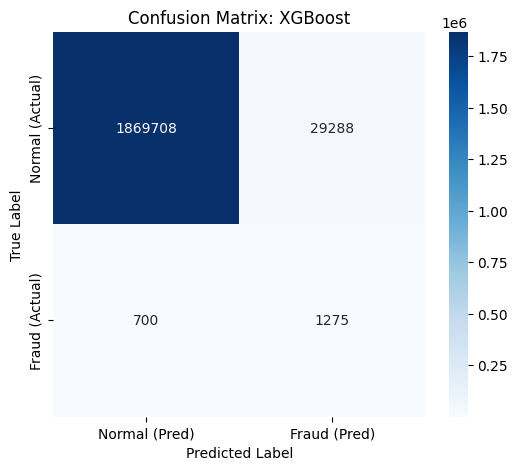

In [43]:
plot_confusion_matrix(Y_Test, xgb_pred, "XGBoost")


In [44]:
#Clustering

In [45]:
x_scaled

array([[ 3.84096824, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712, -0.28513884],
       [ 3.84096824, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712, -0.10709868],
       [ 3.84096824, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712,  0.21727437],
       ...,
       [-0.25204253, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712, -0.28529539],
       [-0.25204253, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712,  0.67276068],
       [-0.25204253, -0.27380109, -0.23389319, ..., -0.36033032,
        -0.28032712,  0.03213406]], shape=(9504852, 33))

In [46]:
#Doing Principal Component Analysis(PCA)
#Helps in dimensionality reduction by removing features that contribute little in variance 

pca = PCA(n_components=25, random_state=42)
x_pca = pca.fit_transform(x_scaled)

print(pca.explained_variance_ratio_.sum())#This is explained variance or the important info retained after pca

0.8513020018382669


In [47]:
print(x_scaled.shape)
print(x_pca.shape)

(9504852, 33)
(9504852, 25)


In [48]:
def map_clusters_to_binary(cluster_labels, y_true):
    y_true = np.array(y_true).ravel() 
    
    mapped_predictions = np.zeros_like(cluster_labels)
    unique_clusters = np.unique(cluster_labels)
    
    for cluster_id in unique_clusters:
        indices = np.where(cluster_labels == cluster_id)[0]
        true_labels_in_cluster = y_true[indices]
            
       # Calculate the percentage of fraud in this cluster
        if len(true_labels_in_cluster) > 0:
            fraud_count = np.sum(true_labels_in_cluster == 1)
            total_count = len(true_labels_in_cluster)
            fraud_ratio = fraud_count / total_count
            
            # If a cluster is more than 0.5% fraud, label the WHOLE cluster as Fraud (1)
            if fraud_ratio > 0.05: 
                mapped_predictions[indices] = 1
            else:
                mapped_predictions[indices] = 0
            
    return mapped_predictions

In [49]:
def map_clusters_to_binary_for_mbkm(cluster_labels, y_true):
    y_true = np.array(y_true).ravel() 
    
    mapped_predictions = np.zeros_like(cluster_labels)
    unique_clusters = np.unique(cluster_labels)
    
    for cluster_id in unique_clusters:
        indices = np.where(cluster_labels == cluster_id)[0]
        
        true_labels_in_cluster = y_true[indices]
            
        if len(true_labels_in_cluster) > 0:
            fraud_count = np.sum(true_labels_in_cluster == 1)
            total_count = len(true_labels_in_cluster)
            fraud_ratio = fraud_count / total_count
            
            if fraud_ratio > 0.001: 
                mapped_predictions[indices] = 1
            else:
                mapped_predictions[indices] = 0
            
    return mapped_predictions

In [50]:
#1 normal K-Means Clustering Very very heavy for this data set.

k = 100

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(x_pca[:10000])

y_kmeans = y[:10000]
kmeans_pred= map_clusters_to_binary(kmeans_labels,y_kmeans)



In [51]:
hc = AgglomerativeClustering(n_clusters=100)
hc_labels = hc.fit_predict(x_pca[:10000])  # reduce data — hierarchical is heavy!
y_hc= y [:10000]
hc_pred = map_clusters_to_binary(hc_labels,y_hc)

In [52]:

sc = SpectralClustering(
    n_clusters=100,
    assign_labels='kmeans',
    random_state=42
)

sc_labels = sc.fit_predict(x_pca[:10000])

y_sc = y[:10000]

sc_pred = map_clusters_to_binary(sc_labels,y_sc)

In [53]:

db = DBSCAN(eps=0.5, min_samples=10, n_jobs=-1)
db_labels = db.fit_predict(x_pca[:200000])

y_dbscan = y [:200000]


db_pred=(db_labels==-1).astype(int)

In [54]:
mini_kmeans = MiniBatchKMeans(
    n_clusters=500,
    batch_size=10000,
    random_state=42,
    n_init=10
)

mini_labels = mini_kmeans.fit_predict(x_pca)

mbkmeans_pred = map_clusters_to_binary_for_mbkm(mini_labels,y)

In [55]:
# Results 


In [56]:
# Mini Batch KMeans
print(classification_report(y,mbkmeans_pred))


              precision    recall  f1-score   support

           0       1.00      0.70      0.83   9494979
           1       0.00      0.77      0.01      9873

    accuracy                           0.70   9504852
   macro avg       0.50      0.74      0.42   9504852
weighted avg       1.00      0.70      0.83   9504852



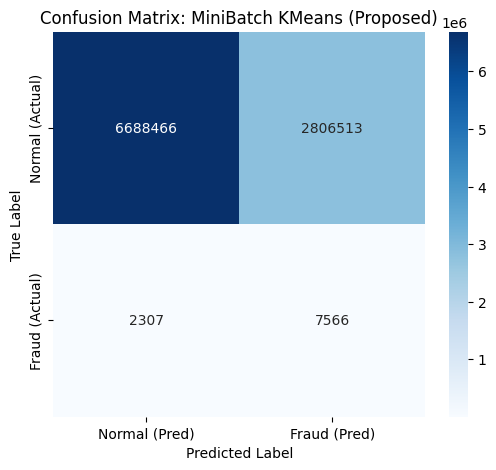

In [57]:
plot_confusion_matrix(y, mbkmeans_pred, "MiniBatch KMeans (Proposed)")


In [58]:
#Kmeans
print(classification_report(y_kmeans,kmeans_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9987
           1       0.17      0.08      0.11        13

    accuracy                           1.00     10000
   macro avg       0.58      0.54      0.55     10000
weighted avg       1.00      1.00      1.00     10000



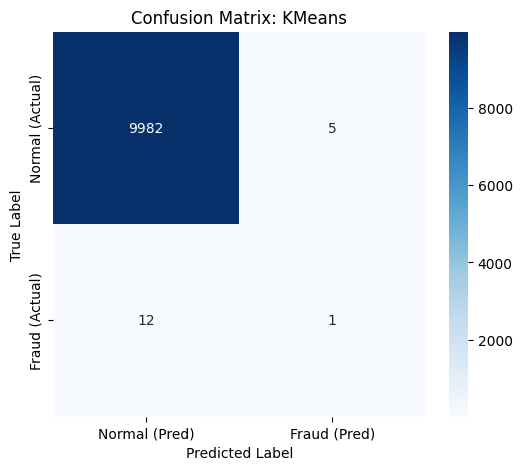

In [59]:
plot_confusion_matrix(y_kmeans, kmeans_pred, "KMeans")


In [60]:
# Hierarchical
print(classification_report(y_hc,hc_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9987
           1       0.00      0.00      0.00        13

    accuracy                           1.00     10000
   macro avg       0.50      0.50      0.50     10000
weighted avg       1.00      1.00      1.00     10000



c:\Users\tambe\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\tambe\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\tambe\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


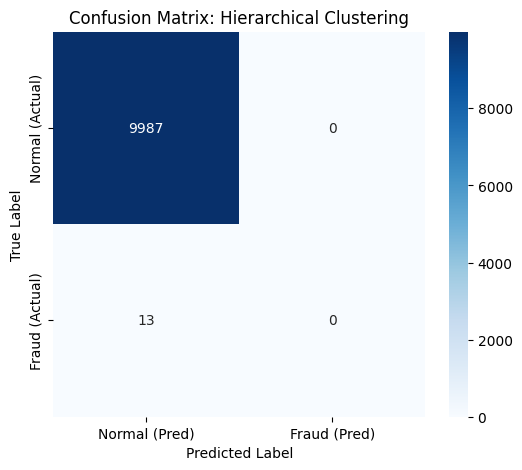

In [61]:
plot_confusion_matrix(y_hc, hc_pred, "Hierarchical Clustering")


In [62]:
#DBSCAN
print(classification_report(y_dbscan,db_pred))

              precision    recall  f1-score   support

           0       1.00      0.88      0.93    199764
           1       0.01      0.72      0.01       236

    accuracy                           0.88    200000
   macro avg       0.50      0.80      0.47    200000
weighted avg       1.00      0.88      0.93    200000



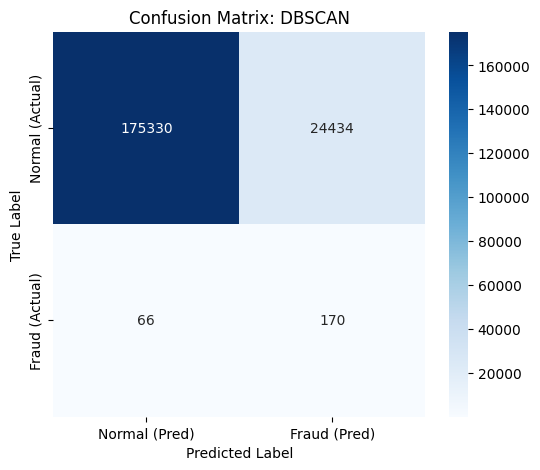

In [63]:
plot_confusion_matrix(y_dbscan, db_pred, "DBSCAN")

In [64]:
# Graph
print(classification_report(y_sc,sc_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9987
           1       0.19      0.31      0.24        13

    accuracy                           1.00     10000
   macro avg       0.59      0.65      0.62     10000
weighted avg       1.00      1.00      1.00     10000



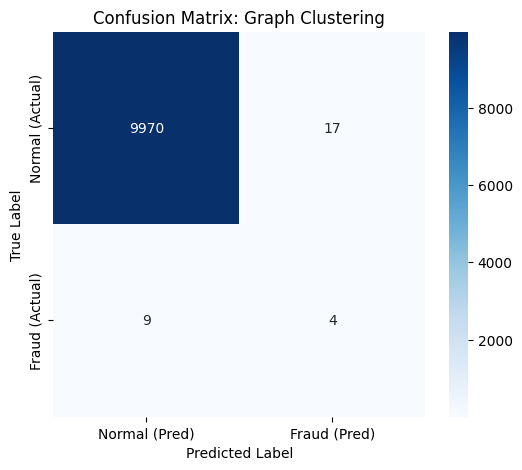

In [65]:
plot_confusion_matrix(y_sc, sc_pred, "Graph Clustering")
